# 16. How much does DMRG cost?

**Goal.** Before you start a big run, how long will it take and how much memory will it need? This notebook builds that estimate from two numbers you measure on your own machine, how fast it multiplies matrices and how much it loses on small calls, plus one counting rule. Each step predicts a time first and then measures it, so you see where the counting works and where it fails. Notebook 12 uses the same counting to price DMRG against a quantum computer.

**Run it on an idle machine.** Every number here is a timing. If other jobs are running, the timings measure them too.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg
from dmrg_from_scratch import finite
from dmrg_from_scratch.finite import apply_heff, grow_left

SMALL = os.environ.get("NB16_SMALL") == "1"  # tiny sizes, only to check that the code runs


def best_time(f, *args, repeats=5):
    """Shortest of several runs of f(*args): the best estimate of what the computation itself costs."""
    times = []
    for _ in range(repeats):
        t = time.perf_counter()
        f(*args)
        times.append(time.perf_counter() - t)
    return min(times)


def thin_svd(M):
    return np.linalg.svd(M, full_matrices=False)

## 1. One number for your machine: how fast it multiplies matrices

A **flop** is one floating-point multiply or add. Multiplying two $n\times n$ matrices takes $n^3$ multiply-adds, so $2n^3$ flops. Time one large product and divide:

In [2]:
n = 300 if SMALL else 2000
a, b = np.random.default_rng(0).standard_normal((2, n, n))
t = best_time(np.matmul, a, b)
peak = 2 * n**3 / t  # flops per second
print(f"n = {n}: {t * 1e3:.1f} ms, so {peak / 1e9:.0f} GFLOP/s")

n = 2000: 18.7 ms, so 854 GFLOP/s


Call this the machine's **peak rate**. NumPy's `@` hands the product to BLAS, a library tuned for this one operation on your processor (on a Mac, Apple's Accelerate; elsewhere OpenBLAS or MKL), and it uses all cores. Everything below is measured against this number.

## 2. Small calls waste the machine

Every call has a fixed cost: Python, checking shapes, allocating the result, starting the threads. For a big product that cost is negligible. For a small one it is all there is:

n =     4:  1.3e+02 flops in       0.5 us =     0.3 GFLOP/s
n =     8:  1.0e+03 flops in       0.5 us =     2.0 GFLOP/s
n =    16:  8.2e+03 flops in       0.9 us =     9.4 GFLOP/s
n =    32:  6.6e+04 flops in       1.1 us =    60.5 GFLOP/s
n =    64:  5.2e+05 flops in       2.4 us =   217.0 GFLOP/s
n =   128:  4.2e+06 flops in      10.5 us =   401.1 GFLOP/s
n =   256:  3.4e+07 flops in      83.3 us =   402.9 GFLOP/s
n =   512:  2.7e+08 flops in     331.3 us =   810.4 GFLOP/s
n =  1024:  2.1e+09 flops in    2652.5 us =   809.6 GFLOP/s
n =  2048:  1.7e+10 flops in   20692.9 us =   830.2 GFLOP/s

smallest call above half the peak rate: about 3e+08 flops


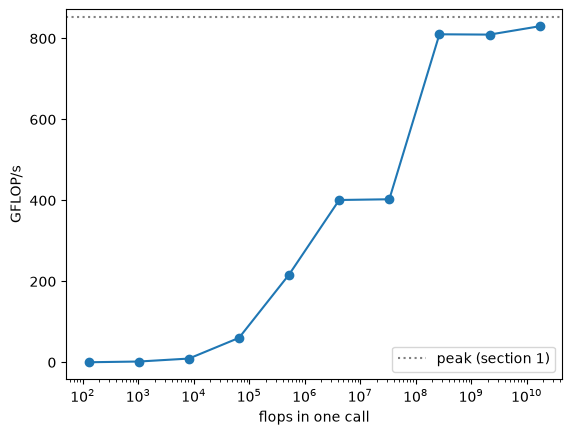

In [3]:
sizes = [4, 8, 16, 32, 64, 128, 256, 512] + ([] if SMALL else [1024, 2048])
flops, rates = [], []
for m in sizes:
    x, y = np.random.default_rng(1).standard_normal((2, m, m))
    t = best_time(np.matmul, x, y, repeats=50 if m <= 128 else 5)
    flops.append(2 * m**3)
    rates.append(2 * m**3 / t)
    print(f"n = {m:5d}: {2 * m**3:8.1e} flops in {t * 1e6:9.1f} us = {rates[-1] / 1e9:7.1f} GFLOP/s")

half = next(f for f, r in zip(flops, rates, strict=True) if r > peak / 2)
print(f"\nsmallest call above half the peak rate: about {half:.0e} flops")
plt.semilogx(flops, np.array(rates) / 1e9, "o-")
plt.axhline(peak / 1e9, color="gray", ls=":", label="peak (section 1)")
plt.xlabel("flops in one call")
plt.ylabel("GFLOP/s")
plt.legend();

Read the curve from the left. The smallest products take about the same few microseconds whatever their size: that is the fixed cost. Only past roughly the printed number of flops per call does the machine run near its peak.

This is the first rule of resource estimation: **the cost of a step is flops divided by the rate, but the rate depends on how big each call is.** Many small calls run far below peak.

A GPU has the same curve, shifted: a much higher peak, but also a much larger fixed cost per call (the call goes to another device, and data may have to be copied there). So a GPU only wins once each call is big. Section 9 measures this if you have one.

## 3. Counting a contraction

The counting rule from the pocket course: **an `einsum` costs the product of the sizes of all the indices it touches**, in multiply-adds (twice that in flops). Each index is counted once, whether it is summed or kept.

`apply_heff`, the matvec $\theta \mapsto H_\text{eff}\theta$, does four contractions. With bond dimension $\chi$, MPO bond dimension $D$ and local dimension $d$:

| step | `einsum` | indices touched | multiply-adds |
|---|---|---|---|
| attach $L$ | `xwy,xpqa->wypqa` | $x, y, a$ ($\chi$); $w$ ($D$); $p, q$ ($d$) | $\chi^3 D d^2$ |
| first $W$ | `wypqa,wutp->uytqa` | $y, a$ ($\chi$); $w, u$ ($D$); $p, q, t$ ($d$) | $\chi^2 D^2 d^3$ |
| second $W$ | `uytqa,uvrq->vytra` | $y, a$ ($\chi$); $u, v$ ($D$); $t, q, r$ ($d$) | $\chi^2 D^2 d^3$ |
| attach $R$ | `vytra,avb->ytrb` | $y, a, b$ ($\chi$); $v$ ($D$); $t, r$ ($d$) | $\chi^3 D d^2$ |

For the TFIM, $D = 3$ and $d = 2$:

In [4]:
def matvec_flops(chi, D, d):
    """Flops of one apply_heff: the four rows of the table, two flops per multiply-add."""
    return 2 * (2 * chi**3 * D * d**2 + 2 * chi**2 * D**2 * d**3)


D, d = 3, 2
for chi in [16, 64, 256, 1024]:
    big, small = 2 * chi**3 * D * d**2, 2 * chi**2 * D**2 * d**3
    print(f"chi = {chi:4d}: attach L and R {2 * big:.1e} flops, the two W steps {2 * small:.1e}"
          f"  ->  L and R are {big / (big + small):.0%} of the work")

chi =   16: attach L and R 2.0e+05 flops, the two W steps 7.4e+04  ->  L and R are 73% of the work
chi =   64: attach L and R 1.3e+07 flops, the two W steps 1.2e+06  ->  L and R are 91% of the work
chi =  256: attach L and R 8.1e+08 flops, the two W steps 1.9e+07  ->  L and R are 98% of the work
chi = 1024: attach L and R 5.2e+10 flops, the two W steps 3.0e+08  ->  L and R are 99% of the work


The two steps that attach $L$ and $R$ are the only ones with three $\chi$ indices, so they dominate as soon as $\chi \gg D d$. That is why the matvec costs $\approx 4\chi^3 D d^2$ flops, the number `dmrg` itself adds up in its `flops` output, and why doubling $\chi$ makes it 8 times slower.

## 4. Predict, then measure: one matvec

The prediction is flops divided by the peak rate. Then measure `apply_heff` twice. As written in `finite.py`, each `einsum` gets `optimize=True`, which lets NumPy reshape the contraction into a matrix product and hand it to BLAS. The second version is the same four `einsum`s without it, so they run in `einsum`'s own loops:

  chi    flops     predicted    einsum loops (x predicted)    apply_heff, BLAS (x predicted)
   16    2.7e+05    3.2e-07 s    7.7e-05 s (  243)        5.4e-05 s (  172)
   32    1.9e+06    2.2e-06 s    2.8e-04 s (  129)        6.5e-05 s (   30)
   64    1.4e+07    1.6e-05 s    1.5e-03 s (   95)        1.5e-04 s (    9)
  128    1.1e+08    1.2e-04 s    9.2e-03 s (   75)        6.1e-04 s (    5)


  256    8.2e+08    9.7e-04 s    6.3e-02 s (   65)        2.8e-03 s (    3)


  512    6.5e+09    7.6e-03 s    4.7e-01 s (   62)        4.4e-02 s (    6)


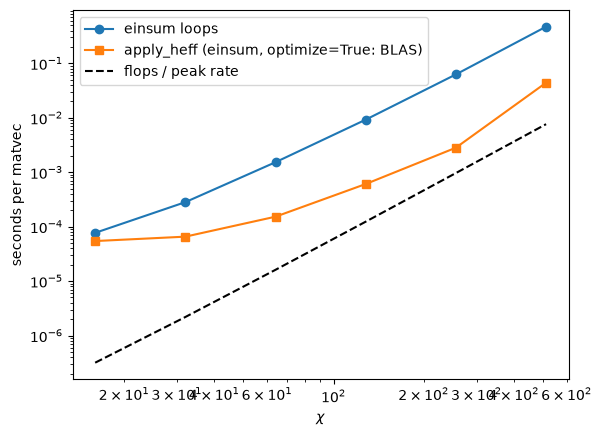

In [5]:
def apply_heff_loops(L, W1, W2, R, theta):
    """The same matvec as apply_heff, without optimize=True: einsum's own loops, no BLAS."""
    T = np.einsum("xwy,xpqa->wypqa", L, theta)
    T = np.einsum("wypqa,wutp->uytqa", T, W1)
    T = np.einsum("uytqa,uvrq->vytra", T, W2)
    return np.einsum("vytra,avb->ytrb", T, R)


rng = np.random.default_rng(2)
W = dmrg.tfim_bulk_tensor(1.0)
chis = [8, 16, 32, 64] if SMALL else [16, 32, 64, 128, 256, 512]
t_loops, t_blas = [], []
print("  chi    flops     predicted    einsum loops (x predicted)    apply_heff, BLAS (x predicted)")
for chi in chis:
    L, R = rng.standard_normal((2, chi, D, chi))
    theta = rng.standard_normal((chi, d, d, chi))
    assert np.allclose(apply_heff(L, W, W, R, theta), apply_heff_loops(L, W, W, R, theta))
    predicted = matvec_flops(chi, D, d) / peak
    t_loops.append(best_time(apply_heff_loops, L, W, W, R, theta, repeats=3))
    t_blas.append(best_time(apply_heff, L, W, W, R, theta))
    te, tb = t_loops[-1], t_blas[-1]
    print(f"{chi:5d}  {matvec_flops(chi, D, d):9.1e}  {predicted:9.1e} s  {te:9.1e} s ({te / predicted:5.0f})"
          f"      {tb:9.1e} s ({tb / predicted:5.0f})")

chis_a = np.array(chis, dtype=float)
plt.loglog(chis, t_loops, "o-", label="einsum loops")
plt.loglog(chis, t_blas, "s-", label="apply_heff (einsum, optimize=True: BLAS)")
plt.loglog(chis, matvec_flops(chis_a, D, d) / peak, "k--", label="flops / peak rate")
plt.xlabel(r"$\chi$")
plt.ylabel("seconds per matvec")
plt.legend();

Three things to read off:

* **The slope.** At large $\chi$ both measured curves run parallel to the dashed line, which has slope 3: the $\chi^3$ of the counting is real.
* **The offset.** Without `optimize=True`, `einsum` does not call BLAS, so it runs far below the peak: the same flops, many times slower. With it, `apply_heff` gets close to the prediction at large $\chi$. This repo writes `einsum` because it reads like the diagrams, and passes `optimize=True` so that it runs at BLAS speed.
* **Small $\chi$.** At small $\chi$ both are slower than predicted, for the reason of section 2: each call is too small to run at peak.

So a prediction from counting is right up to a constant factor, the efficiency of the code, and that factor is worth measuring once.

## 5. Memory

Memory is the other resource, and it is pure counting: a double-precision number takes 8 bytes (16 if complex). What DMRG keeps:

* the MPS: $L$ tensors of $\chi^2 d$ numbers;
* the environments: one $L$ or $R$ block of $\chi^2 D$ numbers per cut, kept for the whole sweep;
* the Lanczos vectors: a few copies of $\theta$, $\chi^2 d^2$ numbers each.

In [6]:
def gigabytes(n_numbers):
    return 8 * n_numbers / 1e9


n_sites = 100
ram = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
print(f"this machine has {ram:.0f} GB of memory\n")
print("   chi    one MPS tensor   all MPS tensors   all environments   one theta")
for chi in [64, 1024, 4096, 16384, 65536]:
    print(f"{chi:6d}   {gigabytes(chi**2 * d):11.2e} GB   {gigabytes(n_sites * chi**2 * d):12.2e} GB"
          f"   {gigabytes(n_sites * chi**2 * D):13.2e} GB   {gigabytes(chi**2 * d**2):9.2e} GB")

this machine has 52 GB of memory

   chi    one MPS tensor   all MPS tensors   all environments   one theta
    64      6.55e-05 GB       6.55e-03 GB        9.83e-03 GB    1.31e-04 GB
  1024      1.68e-02 GB       1.68e+00 GB        2.52e+00 GB    3.36e-02 GB
  4096      2.68e-01 GB       2.68e+01 GB        4.03e+01 GB    5.37e-01 GB
 16384      4.29e+00 GB       4.29e+02 GB        6.44e+02 GB    8.59e+00 GB
 65536      6.87e+01 GB       6.87e+03 GB        1.03e+04 GB    1.37e+02 GB


Memory grows as $\chi^2$, time as $\chi^3$, so time usually runs out first. Not always: at $\chi = 65536$ one MPS tensor alone is about 70 GB, which is why the largest DMRG run so far spread every tensor over 1024 TPU cores (M. Ganahl et al., [arXiv:2204.05693](https://arxiv.org/abs/2204.05693); [PRX Quantum 4, 010317 (2023)](https://doi.org/10.1103/PRXQuantum.4.010317)). Codes with large MPOs (molecules, where $D$ grows as $K^2$, notebook 6) also keep the environments on disk; that is what block2's `scratch` folder is for.

## 6. One local solve: how many matvecs?

Lanczos calls the matvec repeatedly until $\theta$ converges. Count the calls during a real run by wrapping `apply_heff`:

In [7]:
calls = {"n": 0}
original = finite.apply_heff


def counting_apply_heff(*args):
    calls["n"] += 1
    return original(*args)


finite.apply_heff = counting_apply_heff  # solve_two_site looks it up here
L_chain, chi_run, sweeps = (20, 16, 2) if SMALL else (60, 32, 4)
result = dmrg.dmrg(dmrg.tfim_mpo(L_chain, 1.0), chi_run, n_sweeps=sweeps)
finite.apply_heff = original

solves = 2 * (L_chain - 1) * sweeps  # one solve per bond, two half sweeps per sweep
matvecs_per_solve = calls["n"] / solves
print(f"{solves} local solves, {calls['n']} matvecs: {matvecs_per_solve:.0f} per solve")

472 local solves, 15168 matvecs: 32 per solve


A few dozen matvecs per solve is typical, and it barely depends on $\chi$, so it is a constant factor in the estimate. It is smaller when the starting $\theta$ is already good, for example in later sweeps.

## 7. The other steps: the SVD and the environment update

After each solve, DMRG splits $\theta$ with an SVD (a $\chi d \times d\chi$ matrix) and updates one environment with `grow_left` or `grow_right`. Each happens once per bond, while the matvec happens a few dozen times:

In [8]:
print("  chi   matvec x solve      SVD      environment update   SVD share")
for chi in chis:
    L = rng.standard_normal((chi, D, chi))
    theta = rng.standard_normal((chi, d, d, chi))
    A = rng.standard_normal((chi, d, chi))
    t_mv = best_time(apply_heff, L, W, W, L, theta, repeats=3) * matvecs_per_solve
    t_svd = best_time(thin_svd, theta.reshape(chi * d, d * chi), repeats=3)
    t_env = best_time(grow_left, L, A, W, repeats=3)
    print(f"{chi:5d}   {t_mv:9.1e} s   {t_svd:9.1e} s   {t_env:9.1e} s           {t_svd / (t_mv + t_svd + t_env):6.1%}")

  chi   matvec x solve      SVD      environment update   SVD share
   16     3.0e-03 s     8.1e-05 s     3.8e-05 s             2.6%
   32     2.5e-03 s     2.9e-04 s     4.1e-05 s            10.1%
   64     4.9e-03 s     1.2e-03 s     6.4e-05 s            18.8%
  128     2.1e-02 s     4.9e-03 s     2.2e-04 s            19.0%
  256     8.8e-02 s     2.3e-02 s     9.1e-04 s            20.7%


  512     1.4e+00 s     1.2e-01 s     6.6e-03 s             7.3%


The SVD also scales as $\chi^3$ (of a $2\chi\times2\chi$ matrix), but it runs once per bond, while the solve applies the matvec a few dozen times; the last column shows how the two compare on your machine. The faster the matvec, the larger the SVD's share. That is what happens on GPUs, where the SVD is hard to parallelize and often becomes the bottleneck; one fix is to replace it by a QR decomposition (J. Unfried, J. Hauschild and F. Pollmann, [arXiv:2212.09782](https://arxiv.org/abs/2212.09782); [Phys. Rev. B 107, 155133 (2023)](https://doi.org/10.1103/PhysRevB.107.155133)).

## 8. Predict a whole run

Now put the pieces together. Per bond: a solve, an SVD and an environment update. Per sweep: $2(L-1)$ bonds. Bonds near the ends have smaller $\chi$, so using the bulk $\chi$ everywhere gives an upper estimate:

In [9]:
L_chain, chi_run, sweeps = (20, 16, 2) if SMALL else (100, 64, 4)
L = rng.standard_normal((chi_run, D, chi_run))
theta = rng.standard_normal((chi_run, d, d, chi_run))
A = rng.standard_normal((chi_run, d, chi_run))
per_bond = (matvecs_per_solve * best_time(apply_heff, L, W, W, L, theta, repeats=3)
            + best_time(thin_svd, theta.reshape(chi_run * d, d * chi_run), repeats=3)
            + best_time(grow_left, L, A, W, repeats=3))
predicted = 2 * (L_chain - 1) * sweeps * per_bond
print(f"prediction for L = {L_chain}, chi = {chi_run}, {sweeps} sweeps: {predicted:.1f} s (upper estimate)")

result = dmrg.dmrg(dmrg.tfim_mpo(L_chain, 1.0), chi_run, n_sweeps=sweeps)
print(f"measured: {result['seconds']:.1f} s, energy error {result['energy'] - dmrg.tfim_open_energy(L_chain, 1.0):.0e}")
rate = result["flops"] / result["seconds"]
print(f"dmrg counted {result['flops']:.1e} flops in H_eff: {rate / 1e9:.1f} GFLOP/s overall")

prediction for L = 100, chi = 64, 4 sweeps: 5.1 s (upper estimate)


measured: 4.3 s, energy error 7e-13
dmrg counted 1.2e+11 flops in H_eff: 27.4 GFLOP/s overall


The prediction comes out above the measured time, because the bonds near the ends have smaller $\chi$ and are cheaper; the shorter the chain, the larger that effect. If it is far off, one of the pieces is missing: that is the useful part of making a prediction.

## 9. A GPU, if you have one

This section runs only if it finds an NVIDIA GPU through CuPy or PyTorch (`pip install cupy-cuda12x`, or PyTorch with CUDA). It repeats sections 1 and 4 on the GPU, in double and in single precision. Two things to look for:

* **Where the GPU overtakes the CPU.** Below some $\chi$ the GPU is slower, because each call is too small to pay for the fixed cost.
* **Double precision.** Consumer GPUs (GeForce) are built for single precision and are much slower in double; data-centre GPUs (A100, H100) are not. DMRG normally needs double precision.

In [10]:
def find_gpu():
    """Return (name, to_gpu, tensordot, synchronize) for CuPy or PyTorch on CUDA, or None."""
    try:
        import cupy as cp

        if cp.cuda.runtime.getDeviceCount() > 0:
            name = cp.cuda.runtime.getDeviceProperties(0)["name"].decode()
            return name, cp.asarray, cp.tensordot, cp.cuda.Stream.null.synchronize
    except Exception:
        pass
    try:
        import torch

        if torch.cuda.is_available():
            return torch.cuda.get_device_name(0), lambda x: torch.as_tensor(x, device="cuda"), torch.tensordot, \
                torch.cuda.synchronize
    except Exception:
        pass
    return None


gpu = find_gpu()
print("GPU:", gpu[0] if gpu else "none found; skipping this section")

GPU: none found; skipping this section


In [11]:
if gpu:
    name, to_gpu, tdot, sync = gpu

    def gpu_time(f, *args, repeats=5):
        f(*args)
        sync()  # the first call also compiles and allocates; leave it out

        def timed():
            f(*args)
            sync()  # GPU calls return before they finish; wait for them

        return best_time(timed, repeats=repeats)

    for dtype in [np.float64, np.float32]:
        x, y = (to_gpu(m.astype(dtype)) for m in np.random.default_rng(0).standard_normal((2, 4096, 4096)))
        gpu_rate = 2 * 4096**3 / gpu_time(lambda u, v: u @ v, x, y)
        print(f"{np.dtype(dtype).name}: {gpu_rate / 1e9:.0f} GFLOP/s on the GPU (CPU, float64: {peak / 1e9:.0f})")

    def heff_gpu(L, W1, W2, R, theta):
        T = tdot(L, theta, ([0], [0]))
        T = tdot(T, W1, ([0, 2], [0, 3]))
        T = tdot(T, W2, ([3, 1], [0, 3]))
        return tdot(T, R, ([1, 3], [0, 1]))

    print("\n  chi   CPU tensordot    GPU float64    GPU / CPU")
    for chi, t_cpu in zip(chis, t_blas, strict=True):
        L, R = (to_gpu(m) for m in rng.standard_normal((2, chi, D, chi)))
        theta, Wg = to_gpu(rng.standard_normal((chi, d, d, chi))), to_gpu(W)
        t_gpu = gpu_time(heff_gpu, L, Wg, Wg, R, theta)
        print(f"{chi:5d}   {t_cpu:10.1e} s   {t_gpu:10.1e} s   {t_gpu / t_cpu:8.2f}")

Where the last column drops below 1, the GPU wins. Published GPU DMRG codes work far above that point: bond dimensions of $10^4$ for molecules on many GPUs (C. Xiang et al., [arXiv:2311.02854](https://arxiv.org/abs/2311.02854)), and an 80-fold speedup over a 128-core CPU for large active spaces (A. Menczer et al., [arXiv:2407.07411](https://arxiv.org/abs/2407.07411)).

## Rules of thumb

Everything above, in one place. Your own numbers are the printed ones.

1. **Time = flops / rate.** Measure the rate once: a large matrix product gives the peak (section 1).
2. **Small calls run below peak.** Each call has a fixed cost of microseconds; a call needs roughly the flops printed in section 2 to run near peak. A GPU's fixed cost is larger, so it needs bigger calls.
3. **An `einsum` costs the product of all its index sizes** (multiply-adds; twice that in flops). For DMRG the matvec is $\approx 4\chi^3 D d^2$ flops, from attaching $L$ and $R$.
4. **Code efficiency is a constant factor**, measured once (section 4): the same flops through BLAS can be many times faster.
5. **A run = sites × sweeps × (matvecs per solve × matvec + SVD + environment update)**, with a few dozen matvecs per solve.
6. **Memory grows as $\chi^2$, time as $\chi^3$.** Time usually runs out first, until single tensors no longer fit (tens of GB at $\chi$ of a few times $10^4$).
7. **Predict before you run, and compare.** A prediction that is far off means a missing piece.

## Exercises

1. Rewrite the four steps of `apply_heff` with `np.tensordot`, which reshapes each contraction into a matrix product by hand. Is it any faster than `einsum` with `optimize=True`?
2. The two $W$ steps cost $\chi^2 D^2 d^3$. For which $\chi$ do they cost as much as attaching $L$ and $R$? Check with a large $D$, as in quantum chemistry: notebook 6 found $D = 2K^2 + 4K + 3$ for $K$ orbitals.
3. Use section 8's pieces to predict the run time of a χ = 256 run on $L = 100$ before doing it. Then run it.
4. Limit NumPy to one thread (set `VECLIB_MAXIMUM_THREADS=1` on a Mac, `OMP_NUM_THREADS=1` elsewhere, before starting Python) and repeat section 1. How much of the peak came from using all cores?
5. On a GPU machine, find the $\chi$ where the GPU matvec overtakes the CPU in float64, and in float32. Which one is the honest comparison for DMRG?